# __GEH analysis OD Assignment (original demand)__

El índice GEH se usa en modelado de tráfico para comparar los volúmenes de vehículos observados en la realidad con los obtenidos a través de un modelo de simulación.

__Volumen modelado vs volumen observado__

__Formula =__ sqrt(2 * (m - c) ** 2 / (m + c))
- m = volumen modelado
- c = volumen observado (aforo)


In [54]:
import re
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA = "/Users/jeannettearjona/Library/CloudStorage/OneDrive-InstitutoTecnologicoydeEstudiosSuperioresdeMonterrey/Modelación Urbana - Red Vial Guadalajara/Validacion Asignacion/PrT/Link Volumes/061126"
PERIODOS = ["EM","AP", "LM", "EA", "PP","LN"]

# Volumen asignado por periodo en columna VOL_periodo (p.ej. VOL_EM, VOL_AP, etc.)
COL = {
    f"vol_total_{p}": f"VOL_{p}"
    for p in PERIODOS
}

gdf = gpd.read_file(RUTA)
print(gdf.shape)
print(gdf.columns.tolist())

(228854, 16)
['NO', 'FROMNODENO', 'TONODENO', 'TYPENO', 'TSYSSET', 'LENGTH', 'NUMLANES', 'CAPPRT', 'V0PRT', 'VOL_EM', 'VOL_AP', 'VOL_LM', 'VOL_EA', 'VOL_PP', 'VOL_LN', 'geometry']


### 1. Usar los aforos revisados por Daniel

In [55]:
# Archivo con los aforos observados seleccionados como confiables.
# Estos volúmenes se usarán como referencia para evaluar la asignación.
AFOROS_CONFIABLES_TOTALES = r'/Users/jeannettearjona/Library/CloudStorage/OneDrive-InstitutoTecnologicoydeEstudiosSuperioresdeMonterrey/Modelación Urbana - Red Vial Guadalajara/Insumos IMEPLAN/Aforos/SEMÁFOROS/aforos_confiables_calibracion.csv'

# Leer el CSV y quitar el identificador del punto de aforo.
# Para el cruce con la red utilizaremos el link y sus nodos.
aforos_confiables = pd.read_csv(AFOROS_CONFIABLES_TOTALES)
aforos_confiables.drop(columns=["punto_aforo"], inplace=True)
aforos_confiables_wide = (
    aforos_confiables.pivot(
        index=["link_no", "from_node", "to_node"],
        columns="periodo_modelacion",
        values="volumen_depurado_x_peak_factor"
    )
    .add_prefix("volumen_")
    .reset_index()
    .rename_axis(columns=None)
)

# Claves para identificar cada link y su sentido
claves = ["NO", "FROMNODENO", "TONODENO"]

# Preparar aforos nuevos
columnas_periodos = [f"volumen_{p}" for p in PERIODOS]

aforos = (
    aforos_confiables_wide[
        ["link_no", "from_node", "to_node"] + columnas_periodos
    ]
    .rename(columns={
        "link_no": "NO",
        "from_node": "FROMNODENO",
        "to_node": "TONODENO",
        **{f"volumen_{p}": f"AF_OBS_{p}" for p in PERIODOS}
    })
    .copy()
)

# Igualar tipos de identificadores
gdf = gdf.copy()

for clave in claves:
    gdf[clave] = pd.to_numeric(
        gdf[clave], errors="raise"
    ).astype("Int64")

    aforos[clave] = pd.to_numeric(
        aforos[clave], errors="raise"
    ).astype("Int64")

if gdf[claves].isna().any().any():
    raise ValueError("Hay identificadores faltantes en el shapefile")

if aforos[claves].isna().any().any():
    raise ValueError("Hay identificadores faltantes en los aforos")

# Permitir volver a ejecutar la celda sin duplicar columnas
columnas_nuevas = [f"AF_OBS_{p}" for p in PERIODOS]
gdf = gdf.drop(columns=columnas_nuevas, errors="ignore")

# Incorporar aforos nuevos al GeoDataFrame
gdf = gdf.merge(
    aforos,
    on=claves,
    how="left",
    validate="many_to_one"
)

# Indicar que los aforos totales deben leerse de las columnas nuevas
for p in PERIODOS:
    columna = f"AF_OBS_{p}"
    gdf[columna] = pd.to_numeric(gdf[columna], errors="coerce")
    COL[f"aforo_total_{p}"] = columna

    print(
        f"{p}: {gdf[columna].notna().sum():,} links "
        f"con aforo total nuevo"
    )

EM: 337 links con aforo total nuevo
AP: 337 links con aforo total nuevo
LM: 337 links con aforo total nuevo
EA: 337 links con aforo total nuevo
PP: 337 links con aforo total nuevo
LN: 337 links con aforo total nuevo


In [56]:
def v(nombre):
    columna = COL.get(nombre)

    if not isinstance(columna, str) or columna not in gdf.columns:
        raise KeyError(
            f"No se encontró una columna válida para {nombre!r}: {columna!r}"
        )

    # Conservar faltantes como NaN
    return pd.to_numeric(gdf[columna], errors="coerce")


# Identificadores de los links
df = gdf[["NO", "FROMNODENO", "TONODENO"]].copy()

if "TYPENO" in gdf.columns:
    df["TYPENO"] = gdf["TYPENO"]

# Leer únicamente volúmenes totales
for p in PERIODOS:
    df[f"vol_total_{p}"] = v(f"vol_total_{p}")
    df[f"aforo_total_{p}"] = v(f"aforo_total_{p}")

links = df.copy()

print(f"Total links: {len(links):,}")

# Mostrar cuántos links tienen datos válidos por periodo
for p in PERIODOS:
    validos = (
        np.isfinite(links[f"aforo_total_{p}"]) &
        np.isfinite(links[f"vol_total_{p}"]) &
        (links[f"aforo_total_{p}"] > 0) &
        (links[f"vol_total_{p}"] >= 0)
    )

    print(
        f"{p}: {validos.sum():,} links disponibles para comparar"
    )

Total links: 228,854
EM: 337 links disponibles para comparar
AP: 337 links disponibles para comparar
LM: 337 links disponibles para comparar
EA: 337 links disponibles para comparar
PP: 337 links disponibles para comparar
LN: 337 links disponibles para comparar


In [57]:
def geh(m, c):
    return np.sqrt(2 * (m - c) ** 2 / (m + c))


def tabla_por_link(base):
    partes = []

    for p in PERIODOS:
        aforo = f"aforo_total_{p}"
        modelado = f"vol_total_{p}"

        validos = (
            np.isfinite(base[aforo]) &
            np.isfinite(base[modelado]) &
            (base[aforo] > 0) &
            (base[modelado] >= 0)
        )

        sub = base.loc[validos].copy()

        columnas_id = [
            c for c in ["NO", "FROMNODENO", "TONODENO", "TYPENO"]
            if c in sub.columns
        ]
        t = sub[columnas_id].copy()

        t["periodo"] = p
        t["vol_observado"] = sub[aforo]
        t["vol_modelado"] = sub[modelado]
        t["diferencia"] = t["vol_modelado"] - t["vol_observado"]
        t["error_absoluto"] = t["diferencia"].abs()
        t["pct_error"] = (
            t["diferencia"] / t["vol_observado"] * 100
        )
        t["GEH"] = geh(t["vol_modelado"], t["vol_observado"])

        t["rango_GEH"] = pd.cut(
            t["GEH"],
            [-np.inf, 5, 10, np.inf],
            right=False,
            labels=["< 5", "5 - 10", ">= 10"]
        )

        partes.append(t)

    return pd.concat(partes, ignore_index=True)


def resumir(t):
    if t.empty:
        raise ValueError("No hay links con datos válidos para calcular GEH.")

    g = t.groupby("periodo", sort=False, observed=True)

    r = pd.DataFrame({
        "links_con_aforo": g.size(),
        "vol_observado_total": g["vol_observado"].sum(),
        "vol_modelado_total": g["vol_modelado"].sum(),
        "GEH_promedio": g["GEH"].mean(),
        "GEH_mediana": g["GEH"].median(),
        "n_GEH<5": g["GEH"].apply(lambda x: (x < 5).sum()),
        "n_GEH_5a10": g["GEH"].apply(
            lambda x: ((x >= 5) & (x < 10)).sum()
        ),
        "n_GEH>=10": g["GEH"].apply(lambda x: (x >= 10).sum()),
        "sesgo_promedio": g["diferencia"].mean(),
        "pct_error_mediana": g["pct_error"].median(),
    })

    r["dif_total_%"] = (
        (r["vol_modelado_total"] / r["vol_observado_total"] - 1)
        * 100
    )

    for categoria in ["<5", "_5a10", ">=10"]:
        r[f"%_GEH{categoria}"] = (
            r[f"n_GEH{categoria}"] / r["links_con_aforo"] * 100
        )

    r["cumple_85%"] = r["%_GEH<5"] >= 85

    def r2_correlacion(x):
        obs = x["vol_observado"]
        mod = x["vol_modelado"]

        if len(x) < 2 or obs.nunique() < 2 or mod.nunique() < 2:
            return np.nan

        return np.corrcoef(obs, mod)[0, 1] ** 2

    r["R2_correlacion"] = g[
        ["vol_observado", "vol_modelado"]
    ].apply(r2_correlacion)

    return r.reindex(PERIODOS).rename_axis("periodo").reset_index()


# Calcular detalle por link y resumen por periodo
todo_original = tabla_por_link(links)
resumen_original = resumir(todo_original)

#display(todo_original.head())
display(resumen_original.round(2))

,periodo,links_con_aforo,vol_observado_total,vol_modelado_total,GEH_promedio,GEH_mediana,n_GEH<5,n_GEH_5a10,n_GEH>=10,sesgo_promedio,pct_error_mediana,dif_total_%,%_GEH<5,%_GEH_5a10,%_GEH>=10,cumple_85%,R2_correlacion
0,EM,337,50450.72,10496,12.72,13.00,36,81,220,-118.56,-97.26,-79.20,10.68,24.04,65.28,False,0.24
1,AP,337,493058.29,415208,19.48,17.53,53,53,231,-231.01,-26.32,-15.79,15.73,15.73,68.55,False,0.42
2,LM,337,454231.28,188435,27.30,26.33,27,26,284,-788.71,-65.41,-58.52,8.01,7.72,84.27,False,0.25
3,EA,337,543779.33,343132,21.88,19.61,53,40,244,-595.39,-39.44,-36.90,15.73,11.87,72.40,False,0.32
4,PP,337,600014.49,335111,26.09,24.35,31,38,268,-786.06,-51.59,-44.15,9.20,11.28,79.53,False,0.31
5,LN,337,316134.25,95112,27.61,27.02,14,20,303,-655.85,-77.94,-69.91,4.15,5.93,89.91,False,0.25


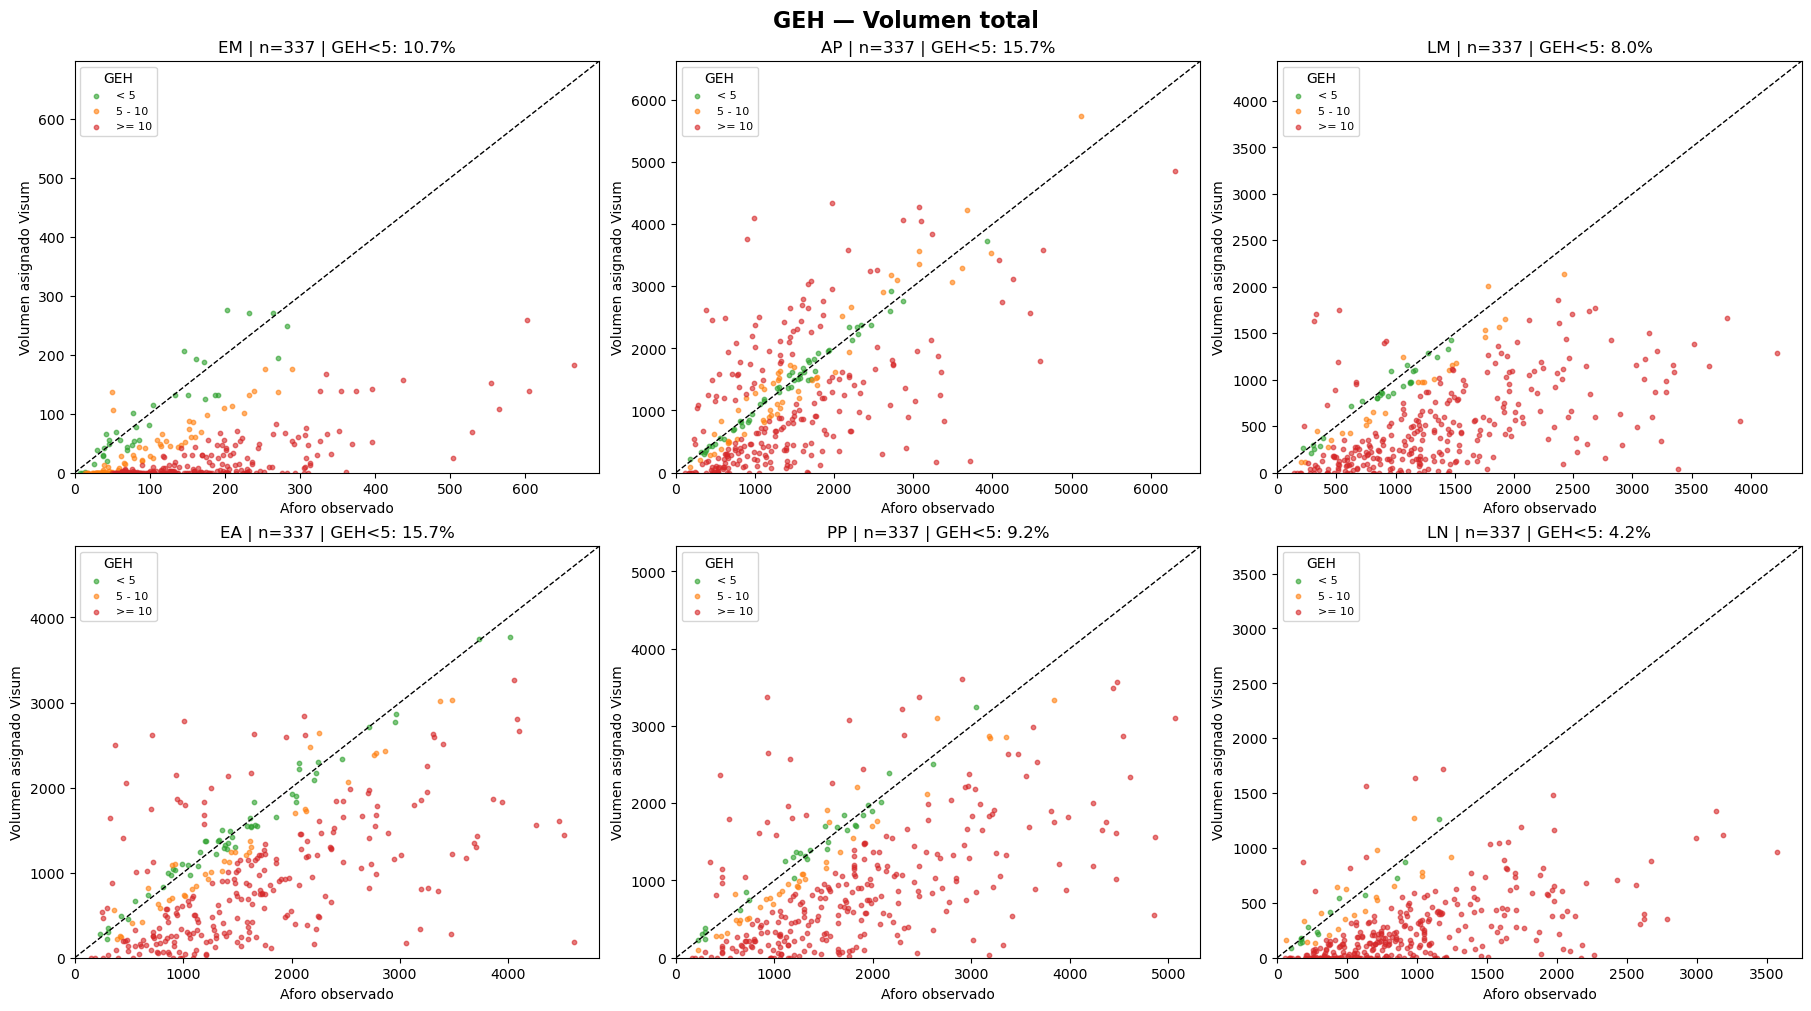

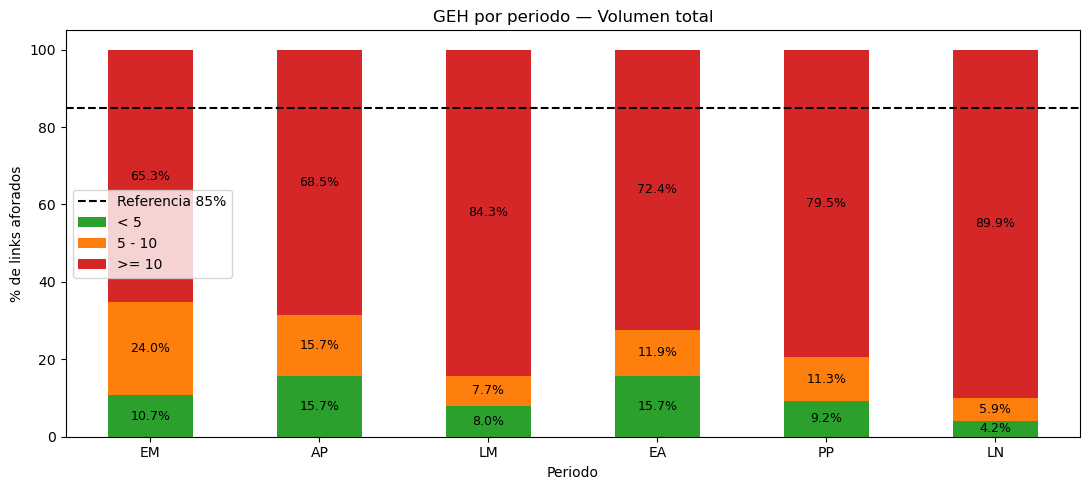

In [58]:
colores = {
    "< 5": "tab:green",
    "5 - 10": "tab:orange",
    ">= 10": "tab:red"
}

periodos = [
    p for p in PERIODOS
    if p in todo_original["periodo"].unique()
]

if not periodos:
    raise ValueError("No hay periodos con datos para graficar.")

# 1. SCATTER PLOTS
n_columnas = min(3, len(periodos))
n_filas = int(np.ceil(len(periodos) / n_columnas))

fig, axes = plt.subplots(
    n_filas,
    n_columnas,
    figsize=(6 * n_columnas, 5 * n_filas),
    constrained_layout=True,
    squeeze=False
)

fig.suptitle(
    "GEH — Volumen total",
    fontsize=16,
    fontweight="bold"
)

for ax, p in zip(axes.flat, periodos):
    d = todo_original[todo_original["periodo"] == p]

    for rango, color in colores.items():
        sub = d[d["rango_GEH"] == rango]

        ax.scatter(
            sub["vol_observado"],
            sub["vol_modelado"],
            s=10,
            alpha=0.6,
            color=color,
            label=rango
        )

    limite = max(
        d["vol_observado"].max(),
        d["vol_modelado"].max()
    ) * 1.05

    ax.plot([0, limite], [0, limite], "k--", lw=1)

    ax.set(
        xlim=(0, limite),
        ylim=(0, limite),
        title=(
            f"{p} | n={len(d):,} | "
            f"GEH<5: {(d['GEH'] < 5).mean():.1%}"
        ),
        xlabel="Aforo observado",
        ylabel="Volumen asignado Visum"
    )

    ax.legend(title="GEH", fontsize=8)

for ax in list(axes.flat)[len(periodos):]:
    ax.set_visible(False)

plt.show()

# 2. BARRAS APILADAS POR PERIODO
columnas_pct = [
    "%_GEH<5",
    "%_GEH_5a10",
    "%_GEH>=10"
]

pct = (
    resumen_original.set_index("periodo")
    .reindex(periodos)[columnas_pct]
    .astype(float)
)

ax = pct.plot.bar(
    stacked=True,
    figsize=(11, 5),
    color=list(colores.values())
)

ax.axhline(
    85,
    color="black",
    linestyle="--",
    label="Referencia 85%"
)

ax.set(
    ylabel="% de links aforados",
    xlabel="Periodo",
    title="GEH por periodo — Volumen total",
    ylim=(0, 105)
)

# Etiquetas de porcentaje dentro de las barras
for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        labels=[
            f"{valor:.1f}%" if valor >= 3 else ""
            for valor in contenedor.datavalues
        ],
        label_type="center",
        fontsize=9
    )

handles, _ = ax.get_legend_handles_labels()
ax.legend(
    handles,
    ["Referencia 85%", "< 5", "5 - 10", ">= 10"]
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# __GEH analysis XTMF Assignment (Toronto demand)__

In [59]:
import re
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path


#ROOT = r'/Users/jeannettearjona/Library/CloudStorage/OneDrive-InstitutoTecnologicoydeEstudiosSuperioresdeMonterrey/Modelación Urbana - Red Vial Guadalajara/GDL 061126/run_061126/AssignedNetworks/links'
ROOT = r'/Users/jeannettearjona/Library/CloudStorage/OneDrive-InstitutoTecnologicoydeEstudiosSuperioresdeMonterrey/Modelación Urbana - Red Vial Guadalajara/XTMF Executions/GDL 161126/Run161126/AssignedNetworks/Links'
PERIODOS = ["EM","AP", "LM", "EA", "PP","LN"]
COL_VOL = "VolVehPrT(AP)"                          # Nombre real de la columna de volumen en cada shapefile

# Columnas de volumen modelado total PrT por periodo (VolVehPrT)
COL_VOL_MANUAL = {
    "EM":"VOLVEHPR~1",
    "AP":"VOLVEHPR~1",
    "LM":"VOLVEHPR~1",
    "EA":"VOLVEHPR~1",
    "PP":"VOLVEHPR~1",
    "LN":"VOLVEHPR~1"
}

# Columnas de aforo agregado por periodo (TOTAL_COUNTS)
COL_AFORO_MANUAL = {
    "EM":"TOTAL_CO~5",
    "AP":"TOTAL_CO~7",
    "LM":"TOTAL_CO~5",
    "EA":"TOTAL_CO~5",
    "PP":"TOTAL_CO~7",
    "LN":"TOTAL_CO~7"
}

### 1. Leer aforos (aggregated) confiables y revisados por Daniel

In [60]:
AFOROS_CONFIABLES_TOTALES = r'/Users/jeannettearjona/Library/CloudStorage/OneDrive-InstitutoTecnologicoydeEstudiosSuperioresdeMonterrey/Modelación Urbana - Red Vial Guadalajara/Insumos IMEPLAN/Aforos/SEMÁFOROS/aforos_confiables_calibracion.csv'

aforos_confiables = pd.read_csv(AFOROS_CONFIABLES_TOTALES)
aforos_confiables.drop(columns=["punto_aforo"], inplace=True)
aforos_confiables_wide = (
    aforos_confiables.pivot(
        index=["link_no", "from_node", "to_node"],
        columns="periodo_modelacion",
        values="volumen_depurado_x_peak_factor"
    )
    .add_prefix("volumen_")
    .reset_index()
    .rename_axis(columns=None)
)
aforos_confiables_wide

,link_no,from_node,to_node,volumen_AP,volumen_EA,volumen_EM,volumen_LM,volumen_LN,volumen_PP
0,4429,1520,1519,803.45,988.57,89.43,768.41,797.12,1237.29
1,7042,2480,2490,236.10,309.81,24.63,236.41,213.15,462.76
2,59826,22482,29273,823.36,869.38,62.68,687.81,506.58,1070.68
3,82603,32534,36338,1411.78,1493.69,156.22,1129.66,800.57,1984.71
4,83754,32909,33053,1482.18,1944.47,307.12,1373.79,1647.79,2650.72
...,...,...,...,...,...,...,...,...,...
332,480615,200619,135786,1673.60,1119.83,201.42,1065.23,841.54,1205.74
333,488084,203582,132688,2096.99,2110.88,310.91,1942.67,1520.42,2319.22
334,489360,204045,135029,314.67,673.31,45.30,386.92,374.17,846.21
335,489556,204109,204100,994.90,861.48,54.49,882.36,372.46,710.79


In [61]:
def buscar_columna(gdf, objetivo, manual=None):
    if manual:
        if manual not in gdf.columns:
            raise KeyError(f"Columna manual {manual!r} no existe")
        return manual
    opciones = [c for c in gdf.columns if c.upper() == objetivo.upper()]
    if len(opciones) == 1:
        return opciones[0]
    raise KeyError(f"No se encontró {objetivo!r}. Columnas disponibles: {list(gdf.columns)}. "
                   "Revisa si el shapefile truncó el nombre a 10 caracteres y usa el diccionario MANUAL.")

def leer_periodo(periodo):

    # 1. Leer shapefile
    ruta = os.path.join(
        ROOT,
        f"Auto{periodo}",
        f"Auto{periodo}_link.shp"
    )
    gdf = gpd.read_file(ruta)

    # 2. Identificar volumen modelado
    col_vol = buscar_columna(
        gdf, COL_VOL, COL_VOL_MANUAL.get(periodo)
    )

    col_obs = f"volumen_{periodo}"
    if col_obs not in aforos_confiables_wide.columns:
        raise KeyError(f"No existe {col_obs!r} en los aforos nuevos")

    # 3. Preparar datos modelados
    claves = ["NO", "FROMNODENO", "TONODENO"]
    cols_id = claves + [
        c for c in ["TYPENO", "GRUPO_CAP"]
        if c in gdf.columns
    ]

    df = gdf[cols_id].copy()
    df["vol_modelado"] = pd.to_numeric(
        gdf[col_vol], errors="coerce"
    )

    # Preparar aforos del periodo
    aforos = (
        aforos_confiables_wide[
            ["link_no", "from_node", "to_node", col_obs]
        ]
        .rename(columns={
            "link_no": "NO",
            "from_node": "FROMNODENO",
            "to_node": "TONODENO",
            col_obs: "vol_observado"
        })
        .copy()
    )

    # Igualar tipos de las claves en ambas tablas
    for columna in claves:
        df[columna] = pd.to_numeric(
            df[columna], errors="raise"
        ).astype("Int64")

        aforos[columna] = pd.to_numeric(
            aforos[columna], errors="raise"
        ).astype("Int64")

    if df[claves].isna().any().any():
        raise ValueError("Hay links con identificadores faltantes")

    if aforos[claves].isna().any().any():
        raise ValueError("Hay aforos con identificadores faltantes")

    aforos["vol_observado"] = pd.to_numeric(
        aforos["vol_observado"], errors="coerce"
    )

    # 4. Cruzar por link y sentido
    n_total = len(df)

    df = df.merge(
        aforos,
        on=claves,
        how="left",
        validate="many_to_one",
        indicator=True
    )

    n_coinciden = df["_merge"].eq("both").sum()
    df = df.drop(columns="_merge")

    # 5. Conservar aforos positivos y modelados no negativos
    validos = (
        np.isfinite(df["vol_observado"]) &
        np.isfinite(df["vol_modelado"]) &
        (df["vol_observado"] > 0) &
        (df["vol_modelado"] >= 0)
    )
    df = df.loc[validos].copy()

    print(
        f"{periodo} | {modo}: {col_vol} vs {col_obs} | "
        f"Links que coinciden con aforos nuevos: {n_coinciden:,}/{n_total:,} | "
        f"Links válidos para GEH: {len(df):,}"
    )

    # 6. Métricas
    df["periodo"] = periodo
    df["modo"] = modo
    df["diferencia"] = df["vol_modelado"] - df["vol_observado"]
    df["error_absoluto"] = df["diferencia"].abs()
    df["pct_error"] = (
        df["diferencia"] / df["vol_observado"] * 100
    )

    df["GEH"] = np.sqrt(
        2 * df["diferencia"]**2 /
        (df["vol_modelado"] + df["vol_observado"])
    )

    df["rango_GEH"] = pd.cut(
        df["GEH"],
        [-np.inf, 5, 10, np.inf],
        right=False,
        labels=["< 5", "5 - 10", ">= 10"]
    )

    return df

In [63]:
partes = []

for periodo in PERIODOS:
        df = leer_periodo(periodo)

        if df is not None:
            partes.append(df)

if not partes:
    raise ValueError("No se encontraron datos válidos.")

todo_xtmf = pd.concat(partes, ignore_index=True)

display(todo_xtmf.head())


EM | TOTAL: VOLVEHPR~1 vs volumen_EM | Links que coinciden con aforos nuevos: 337/228,854 | Links válidos para GEH: 337
AP | TOTAL: VOLVEHPR~1 vs volumen_AP | Links que coinciden con aforos nuevos: 337/228,854 | Links válidos para GEH: 337
LM | TOTAL: VOLVEHPR~1 vs volumen_LM | Links que coinciden con aforos nuevos: 337/228,854 | Links válidos para GEH: 337
EA | TOTAL: VOLVEHPR~1 vs volumen_EA | Links que coinciden con aforos nuevos: 337/228,854 | Links válidos para GEH: 337
PP | TOTAL: VOLVEHPR~1 vs volumen_PP | Links que coinciden con aforos nuevos: 337/228,854 | Links válidos para GEH: 337
LN | TOTAL: VOLVEHPR~1 vs volumen_LN | Links que coinciden con aforos nuevos: 337/228,854 | Links válidos para GEH: 337


,NO,FROMNODENO,TONODENO,TYPENO,GRUPO_CAP,vol_modelado,vol_observado,periodo,modo,diferencia,error_absoluto,pct_error,GEH,rango_GEH
0,4429,1520,1519,302,MEN,0,89.43,EM,TOTAL,-89.43,89.43,-100.000000,13.373855,>= 10
1,7042,2480,2490,402,COL,0,24.63,EM,TOTAL,-24.63,24.63,-100.000000,7.018547,5 - 10
2,59826,22482,29273,302,MEN,0,62.68,EM,TOTAL,-62.68,62.68,-100.000000,11.196428,>= 10
3,82603,32534,36338,103,CARR,5,156.22,EM,TOTAL,-151.22,151.22,-96.799385,16.842819,>= 10
4,83754,32909,33053,103,CARR,0,307.12,EM,TOTAL,-307.12,307.12,-100.000000,24.783866,>= 10


In [64]:
def resumir(d):
    obs, mod = d.vol_observado, d.vol_modelado
    r = np.corrcoef(obs, mod)[0,1] if len(d)>1 and obs.std()>0 and mod.std()>0 else np.nan
    return pd.Series({
        "links_con_aforo": len(d),
        "vol_observado_total": obs.sum(), "vol_modelado_total": mod.sum(),
        "dif_total_%": (
            (mod.sum() / obs.sum() - 1) * 100
            if obs.sum() > 0 else np.nan
        ),
        "GEH_promedio": d.GEH.mean(), "GEH_mediana": d.GEH.median(),
        "n_GEH<5": (d.GEH<5).sum(),
        "n_GEH_5a10": ((d.GEH>=5)&(d.GEH<10)).sum(),
        "n_GEH>=10": (d.GEH>=10).sum(),
        "%_GEH<5": (d.GEH<5).mean()*100,
        "%_GEH_5a10": ((d.GEH>=5)&(d.GEH<10)).mean()*100,
        "%_GEH>=10": (d.GEH>=10).mean()*100,
        "cumple_85%": (d.GEH<5).mean()>=.85,
        "sesgo_promedio": d.diferencia.mean(),
        "pct_error_mediana": d.pct_error.median(),
        "MAE": d.error_absoluto.mean(), "RMSE": np.sqrt(np.mean(d.diferencia**2)),
        "R2_correlacion": r**2,
    })


resumen_xtmf = (
    todo_xtmf.groupby(["periodo", "modo"])
        .apply(resumir, include_groups=False)
        .reset_index()
)
# Ordenar por periodo y modo
resumen_xtmf["periodo"] = pd.Categorical(
    resumen_xtmf["periodo"],
    categories=PERIODOS,
    ordered=True
)

resumen_xtmf = resumen_xtmf.sort_values(["periodo", "modo"])

display(resumen_xtmf.round(2))

,periodo,modo,links_con_aforo,vol_observado_total,vol_modelado_total,dif_total_%,GEH_promedio,GEH_mediana,n_GEH<5,n_GEH_5a10,n_GEH>=10,%_GEH<5,%_GEH_5a10,%_GEH>=10,cumple_85%,sesgo_promedio,pct_error_mediana,MAE,RMSE,R2_correlacion
2,EM,TOTAL,337,50450.72,1955,-96.12,15.68,15.39,6,56,275,1.78,16.62,81.60,False,-143.90,-100.00,144.86,177.94,0.06
0,AP,TOTAL,337,493058.29,490815,-0.45,21.25,18.84,49,42,246,14.54,12.46,73.00,False,-6.66,-9.64,746.89,993.79,0.38
3,LM,TOTAL,337,454231.28,212392,-53.24,27.24,26.13,32,23,282,9.50,6.82,83.68,False,-717.62,-65.09,830.65,1046.29,0.18
1,EA,TOTAL,337,543779.33,413976,-23.87,21.38,17.69,52,55,230,15.43,16.32,68.25,False,-385.17,-26.47,742.19,978.68,0.29
5,PP,TOTAL,337,600014.49,383685,-36.05,25.17,22.24,38,44,255,11.28,13.06,75.67,False,-641.93,-42.67,899.43,1160.25,0.30
4,LN,TOTAL,337,316134.25,78321,-75.23,30.41,29.56,12,16,309,3.56,4.75,91.69,False,-705.68,-89.81,731.88,899.59,0.20


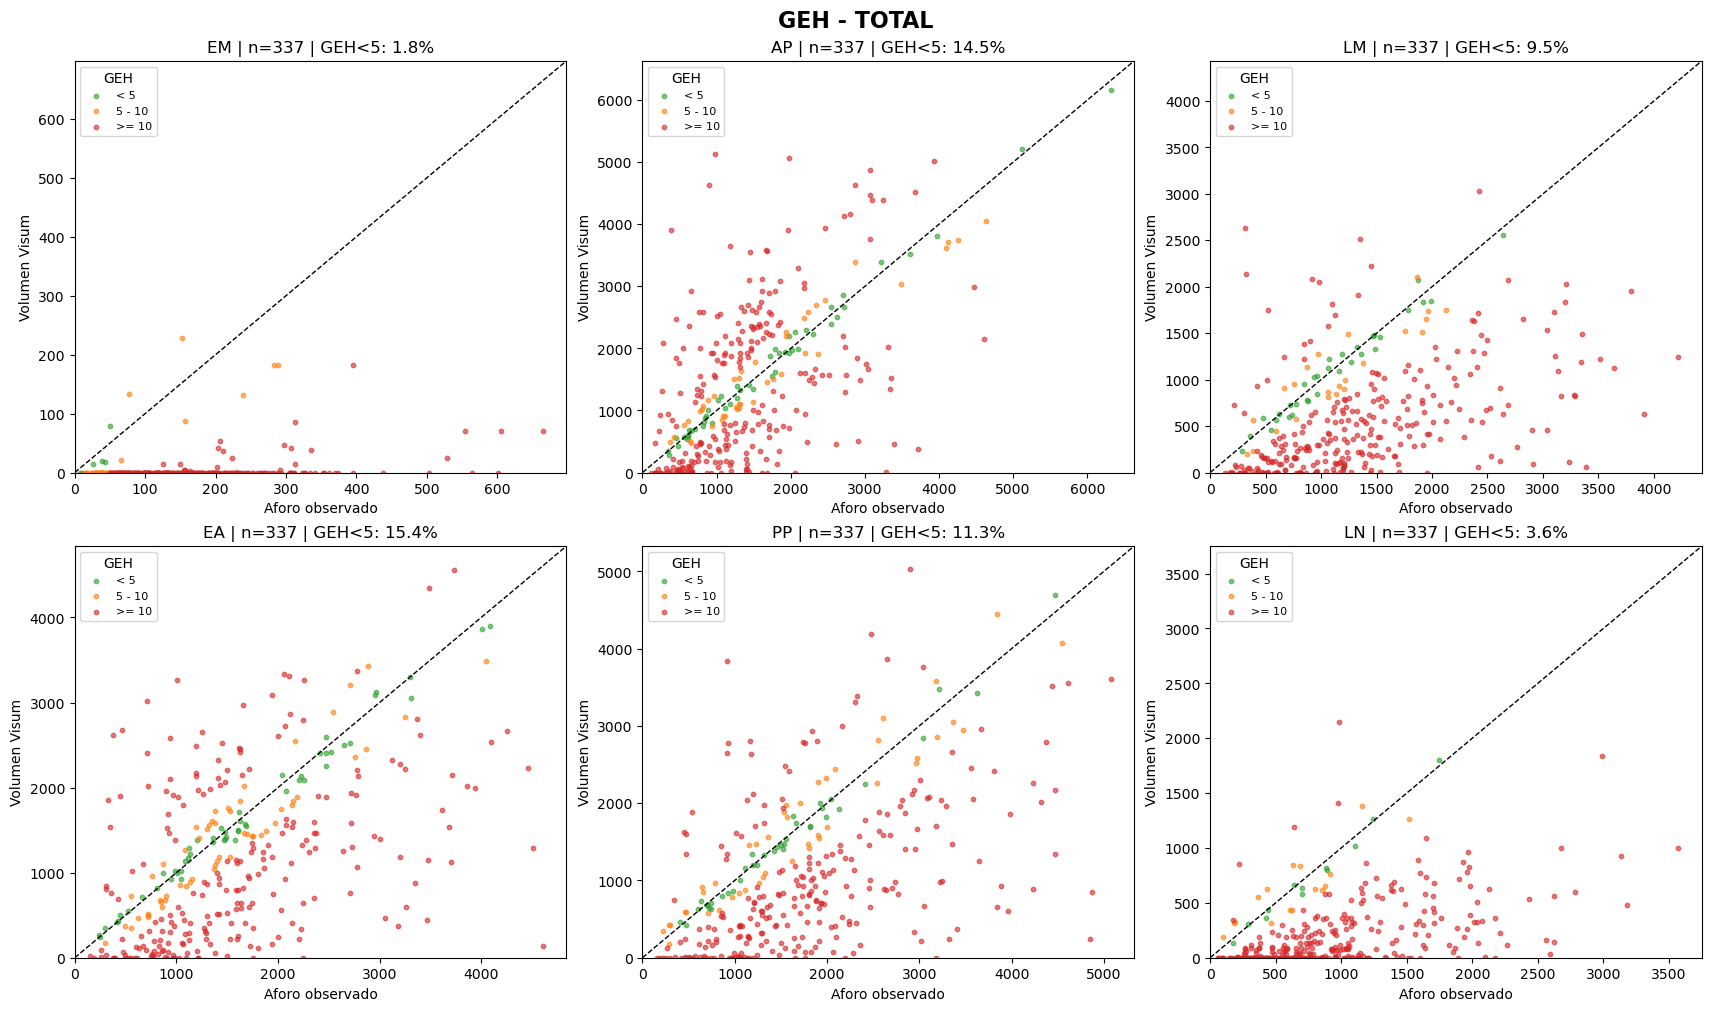

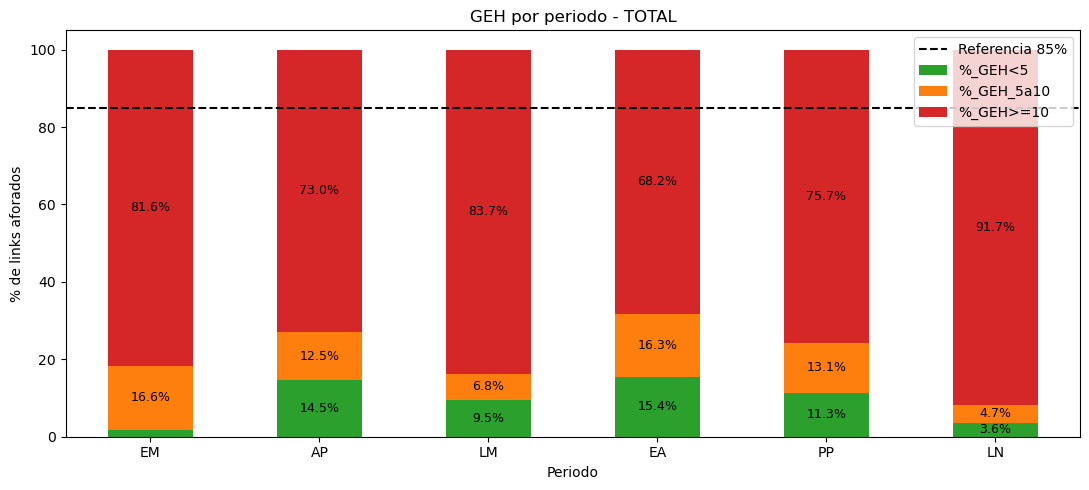

In [65]:
colores = {
    "< 5": "tab:green",
    "5 - 10": "tab:orange",
    ">= 10": "tab:red"
}

for modo in ["TOTAL"]:

    # Filtrar únicamente el modo actual
    datos_modo = todo_xtmf[todo_xtmf["modo"] == modo]

    periodos = [
        p for p in PERIODOS
        if p in datos_modo["periodo"].unique()
    ]

    if not periodos:
        continue

    # ==========================================
    # 1. SCATTER PLOTS
    # ==========================================

    fig, axes = plt.subplots(
        2, 3,
        figsize=(17, 10),
        constrained_layout=True
    )

    fig.suptitle(
        f"GEH - {modo}",
        fontsize=16,
        fontweight="bold"
    )

    for ax, p in zip(axes.flat, periodos):

        d = datos_modo[datos_modo["periodo"] == p]

        for rango, color in colores.items():

            sub = d[d["rango_GEH"].astype(str) == rango]

            ax.scatter(
                sub["vol_observado"],
                sub["vol_modelado"],
                s=10,
                alpha=0.6,
                color=color,
                label=rango
            )

        # Línea de ajuste perfecto (modelado = observado)
        limite = max(
            d["vol_observado"].max(),
            d["vol_modelado"].max()
        ) * 1.05

        ax.plot(
            [0, limite],
            [0, limite],
            "k--",
            lw=1
        )

        ax.set(
            xlim=(0, limite),
            ylim=(0, limite),
            title=(
                f"{p} | n={len(d):,} | "
                f"GEH<5: {(d.GEH < 5).mean():.1%}"
            ),
            xlabel="Aforo observado",
            ylabel="Volumen Visum"
        )

        ax.legend(title="GEH", fontsize=8)

    # Ocultar subplots sin datos
    for ax in axes.flat[len(periodos):]:
        ax.set_visible(False)

    plt.show()

    # ==========================================
    # 2. BARRAS APILADAS POR PERIODO
    # ==========================================

    columnas_pct = [
        "%_GEH<5",
        "%_GEH_5a10",
        "%_GEH>=10"
    ]

    pct = (
        resumen_xtmf[resumen_xtmf["modo"] == modo]
        .set_index("periodo")
        .reindex(periodos)[columnas_pct]
        .astype(float)
    )

    ax = pct.plot.bar(
        stacked=True,
        figsize=(11, 5),
        color=[
            "tab:green",
            "tab:orange",
            "tab:red"
        ]
    )

    #  Porcentajes dentro de cada segmento
    for contenedor in ax.containers:
        ax.bar_label(
            contenedor,
            labels=[
                f"{valor:.1f}%" if valor >= 3 else ""
                for valor in contenedor.datavalues
            ],
            label_type="center",
            fontsize=9
        )

    ax.axhline(
        85,
        color="black",
        linestyle="--",
        label="Referencia 85%"
    )

    ax.set(
        ylabel="% de links aforados",
        xlabel="Periodo",
        title=f"GEH por periodo - {modo}"
    )

    ax.legend()
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

# __ORIGINAL VS XTMF__
- comparativa

In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PERIODOS_COMPARAR = list(PERIODOS)
CLAVES = ["NO", "FROMNODENO", "TONODENO", "periodo"]


def preparar_comparacion(tabla):
    t = tabla.copy()

    # XTMF tiene modo; Original puede no tenerlo
    if "modo" in t.columns:
        t = t[t["modo"] == "TOTAL"].copy()

    t = t[t["periodo"].isin(PERIODOS_COMPARAR)].copy()

    for columna in CLAVES[:3]:
        t[columna] = pd.to_numeric(
            t[columna], errors="raise"
        ).astype("Int64")

    if t[CLAVES].isna().any().any():
        raise ValueError("Hay identificadores o periodos faltantes.")

    for columna in ["vol_observado", "vol_modelado"]:
        t[columna] = pd.to_numeric(t[columna], errors="coerce")

    validos = (
        np.isfinite(t["vol_observado"]) &
        np.isfinite(t["vol_modelado"]) &
        (t["vol_observado"] > 0) &
        (t["vol_modelado"] >= 0)
    )

    return t.loc[
        validos, CLAVES + ["vol_observado", "vol_modelado"]
    ].copy()


original = preparar_comparacion(todo_original)
xtmf = preparar_comparacion(todo_xtmf)

comparacion = original.merge(
    xtmf,
    on=CLAVES,
    how="inner",
    suffixes=("_original", "_xtmf"),
    validate="one_to_one"
)

if comparacion.empty:
    raise ValueError("No hay links y periodos comunes entre los escenarios.")

# Los dos escenarios deben compararse contra el mismo aforo
mismo_aforo = np.isclose(
    comparacion["vol_observado_original"],
    comparacion["vol_observado_xtmf"],
    rtol=0,
    atol=1e-6
)

if not mismo_aforo.all():
    raise ValueError(
        f"Hay {(~mismo_aforo).sum()} registros con aforos distintos. "
        "Actualiza ambos escenarios con los mismos observados."
    )

comparacion["vol_observado"] = comparacion["vol_observado_original"]

# Recalcular métricas sobre los registros comunes
for escenario in ["original", "xtmf"]:
    observado = comparacion["vol_observado"]
    modelado = comparacion[f"vol_modelado_{escenario}"]
    diferencia = modelado - observado

    comparacion[f"diferencia_{escenario}"] = diferencia
    comparacion[f"GEH_{escenario}"] = np.sqrt(
        2 * diferencia**2 / (modelado + observado)
    )

periodos = [
    p for p in PERIODOS_COMPARAR
    if p in comparacion["periodo"].unique()
]

# Ver cuántos registros se están comparando
cobertura = pd.DataFrame({
    "Original válidos": original.groupby("periodo").size(),
    "XTMF válidos": xtmf.groupby("periodo").size(),
    "Comunes": comparacion.groupby("periodo").size()
}).reindex(PERIODOS_COMPARAR).fillna(0).astype(int)

display(cobertura)

# Resumen calculado exclusivamente con links comunes
filas = []

for p in periodos:
    d = comparacion[comparacion["periodo"] == p]

    for escenario in ["original", "xtmf"]:
        errores = d[f"diferencia_{escenario}"]
        valores_geh = d[f"GEH_{escenario}"]

        filas.append({
            "periodo": p,
            "escenario": escenario,
            "links": len(d),
            "%_GEH<5": (valores_geh < 5).mean() * 100,
            "%_GEH_5a10": (
                (valores_geh >= 5) & (valores_geh < 10)
            ).mean() * 100,
            "%_GEH>=10": (valores_geh >= 10).mean() * 100,
            "GEH_mediana": valores_geh.median(),
            "MAE": errores.abs().mean(),
            "RMSE": np.sqrt((errores**2).mean()),
            "sesgo_promedio": errores.mean()
        })

resumen_comun = pd.DataFrame(filas)

,Original válidos,XTMF válidos,Comunes
periodo,,,
EM,337,337,337
AP,337,337,337
LM,337,337,337
EA,337,337,337
PP,337,337,337
LN,337,337,337


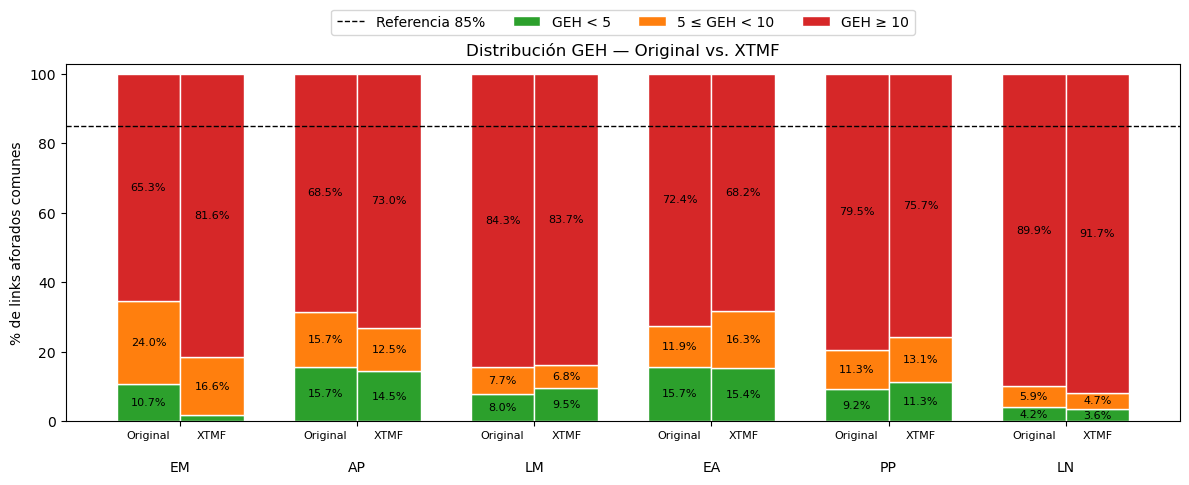

In [67]:
categorias = ["%_GEH<5", "%_GEH_5a10", "%_GEH>=10"]
colores = ["tab:green", "tab:orange", "tab:red"]
etiquetas = ["GEH < 5", "5 ≤ GEH < 10", "GEH ≥ 10"]

x = np.arange(len(periodos))
ancho = 0.36

fig, ax = plt.subplots(figsize=(12, 5))

for escenario, desplazamiento, nombre in [
    ("original", -ancho / 2, "Original"),
    ("xtmf", ancho / 2, "XTMF")
]:
    t = (
        resumen_comun[resumen_comun["escenario"] == escenario]
        .set_index("periodo")
        .reindex(periodos)
    )

    fondo = np.zeros(len(periodos))

    for columna, color, etiqueta in zip(
        categorias, colores, etiquetas
    ):
        valores = t[columna].to_numpy()

        barras = ax.bar(
            x + desplazamiento,
            valores,
            width=ancho,
            bottom=fondo,
            color=color,
            edgecolor="white",
            label=etiqueta if escenario == "original" else None
        )

        ax.bar_label(
            barras,
            labels=[
                f"{v:.1f}%" if v >= 3 else ""
                for v in valores
            ],
            label_type="center",
            fontsize=8
        )

        fondo += valores

    # Nombre del escenario bajo cada barra
    for posicion in x + desplazamiento:
        ax.text(
            posicion, -0.025, nombre,
            transform=ax.get_xaxis_transform(),
            ha="center", va="top", fontsize=8
        )

ax.axhline(
    85, color="black", linestyle="--",
    linewidth=1, label="Referencia 85%"
)

ax.set_xticks(x)
ax.set_xticklabels(periodos)
ax.tick_params(axis="x", pad=25)

ax.set(
    ylim=(0, 103),
    ylabel="% de links aforados comunes",
    title="Distribución GEH — Original vs. XTMF"
)

ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.17), ncol=4)
plt.tight_layout()
plt.show()

In [46]:
tabla_comparativa = pd.DataFrame(index=periodos)
tabla_comparativa.index.name = "Periodo"

tabla_comparativa["Links comunes"] = (
    comparacion.groupby("periodo").size().reindex(periodos)
)

metricas = {
    "%_GEH<5": "% GEH<5",
    "GEH_mediana": "GEH mediano",
    "MAE": "MAE",
    "RMSE": "RMSE",
    "sesgo_promedio": "Sesgo promedio"
}

for metrica, etiqueta in metricas.items():
    t = (
        resumen_comun.pivot(
            index="periodo",
            columns="escenario",
            values=metrica
        )
        .reindex(periodos)
    )

    tabla_comparativa[f"{etiqueta} Original"] = t["original"]
    tabla_comparativa[f"{etiqueta} XTMF"] = t["xtmf"]

    nombre_cambio = (
        "Cambio GEH<5 (puntos porcentuales)"
        if metrica == "%_GEH<5"
        else f"Cambio {etiqueta}"
    )

    tabla_comparativa[nombre_cambio] = t["xtmf"] - t["original"]

display(tabla_comparativa.round(2))

,Links comunes,% GEH<5 Original,% GEH<5 XTMF,Cambio GEH<5 (puntos porcentuales),GEH mediano Original,GEH mediano XTMF,Cambio GEH mediano,MAE Original,MAE XTMF,Cambio MAE,RMSE Original,RMSE XTMF,Cambio RMSE,Sesgo promedio Original,Sesgo promedio XTMF,Cambio Sesgo promedio
Periodo,,,,,,,,,,,,,,,,
EM,337,10.68,1.78,-8.90,13.00,15.41,2.41,121.32,145.04,23.72,151.59,178.11,26.53,-118.56,-144.54,-25.98
AP,337,15.73,13.95,-1.78,17.53,17.34,-0.18,661.27,693.71,32.44,882.22,912.89,30.68,-231.01,-139.79,91.22
LM,337,8.01,9.50,1.48,26.33,25.30,-1.03,836.63,820.61,-16.02,1048.34,1036.73,-11.61,-788.71,-711.24,77.47
EA,337,15.73,15.73,0.00,19.61,17.75,-1.87,756.66,727.62,-29.03,995.92,959.47,-36.45,-595.39,-443.41,151.98
PP,337,9.20,9.50,0.30,24.35,23.90,-0.46,936.32,923.41,-12.91,1180.95,1170.67,-10.28,-786.06,-722.39,63.67
LN,337,4.15,2.37,-1.78,27.02,30.99,3.97,687.25,755.16,67.91,847.76,923.37,75.61,-655.85,-736.00,-80.15


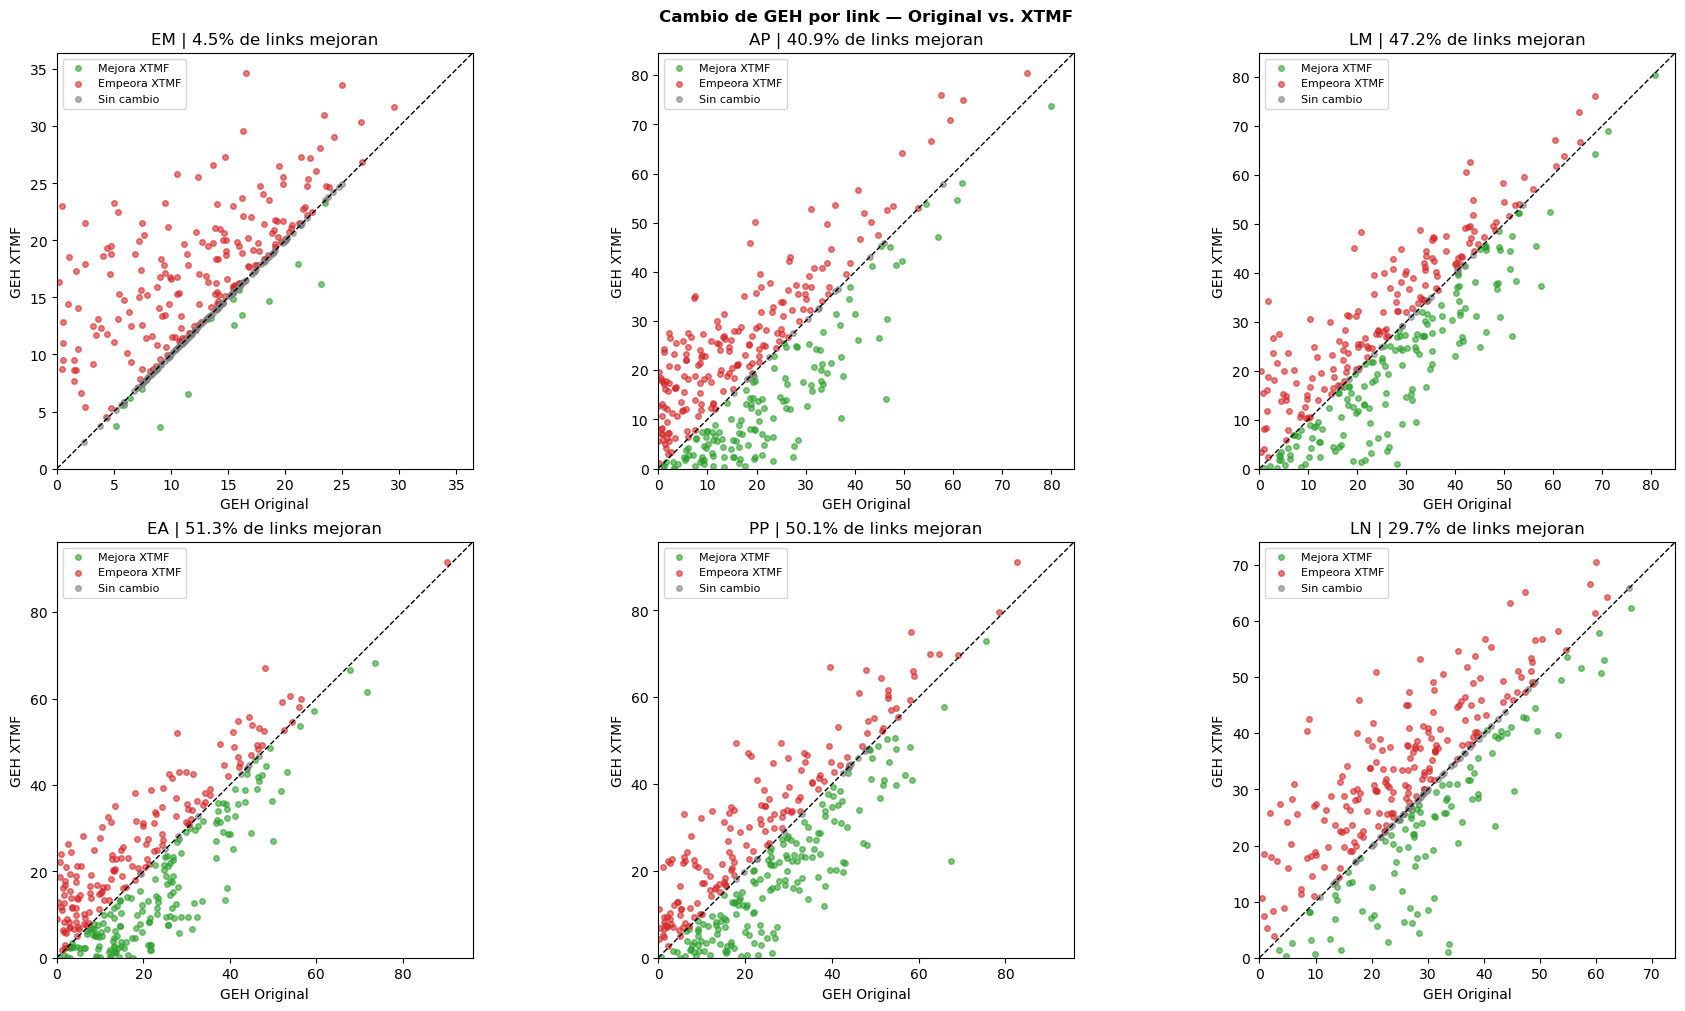

,Periodo,Links comunes,% mejora XTMF,% empeora XTMF,% sin cambio
0,EM,337,4.45,58.16,37.39
1,AP,337,40.95,54.90,4.15
2,LM,337,47.18,48.07,4.75
3,EA,337,51.34,46.29,2.37
4,PP,337,50.15,45.70,4.15
5,LN,337,29.67,56.08,14.24


In [68]:
n_columnas = min(3, len(periodos))
n_filas = int(np.ceil(len(periodos) / n_columnas))

fig, axes = plt.subplots(
    n_filas,
    n_columnas,
    figsize=(6 * n_columnas, 5 * n_filas),
    squeeze=False,
    constrained_layout=True
)

filas_cambios = []

for ax, p in zip(axes.flat, periodos):
    d = comparacion[comparacion["periodo"] == p]

    geh_original = d["GEH_original"]
    geh_xtmf = d["GEH_xtmf"]

    iguales = np.isclose(
        geh_original, geh_xtmf,
        rtol=0, atol=1e-6
    )
    mejora = (geh_xtmf < geh_original) & ~iguales
    empeora = (geh_xtmf > geh_original) & ~iguales

    for mascara, color, etiqueta in [
        (mejora, "tab:green", "Mejora XTMF"),
        (empeora, "tab:red", "Empeora XTMF"),
        (iguales, "gray", "Sin cambio")
    ]:
        ax.scatter(
            geh_original[mascara],
            geh_xtmf[mascara],
            s=16,
            alpha=0.6,
            color=color,
            label=etiqueta
        )

    limite = max(geh_original.max(), geh_xtmf.max(), 1) * 1.05

    ax.plot([0, limite], [0, limite], "k--", linewidth=1)

    ax.set(
        xlim=(0, limite),
        ylim=(0, limite),
        xlabel="GEH Original",
        ylabel="GEH XTMF",
        title=f"{p} | {mejora.mean():.1%} de links mejoran"
    )
    ax.set_aspect("equal", adjustable="box")
    ax.legend(fontsize=8)

    filas_cambios.append({
        "Periodo": p,
        "Links comunes": len(d),
        "% mejora XTMF": mejora.mean() * 100,
        "% empeora XTMF": empeora.mean() * 100,
        "% sin cambio": iguales.mean() * 100
    })

for ax in list(axes.flat)[len(periodos):]:
    ax.set_visible(False)

fig.suptitle(
    "Cambio de GEH por link — Original vs. XTMF",
    fontweight="bold"
)
plt.show()

cambios_por_link = pd.DataFrame(filas_cambios)
display(cambios_por_link.round(2))

In [69]:
detalle_cambios = comparacion.copy()

detalle_cambios["Cambio GEH"] = (
    detalle_cambios["GEH_xtmf"] -
    detalle_cambios["GEH_original"]
)

detalle_cambios["Magnitud cambio GEH"] = (
    detalle_cambios["Cambio GEH"].abs()
)

sin_cambio = np.isclose(
    detalle_cambios["Cambio GEH"],
    0,
    rtol=0,
    atol=1e-6
)

detalle_cambios["Resultado"] = np.select(
    [
        sin_cambio,
        detalle_cambios["Cambio GEH"] < 0
    ],
    [
        "Sin cambio",
        "Mejora"
    ],
    default="Empeora"
)

# También mostrar el error en unidades de volumen
detalle_cambios["Error absoluto Original"] = (
    detalle_cambios["vol_modelado_original"] -
    detalle_cambios["vol_observado"]
).abs()

detalle_cambios["Error absoluto XTMF"] = (
    detalle_cambios["vol_modelado_xtmf"] -
    detalle_cambios["vol_observado"]
).abs()

columnas = [
    "periodo", "NO", "FROMNODENO", "TONODENO",
    "vol_observado",
    "vol_modelado_original", "vol_modelado_xtmf",
    "GEH_original", "GEH_xtmf",
    "Cambio GEH", "Resultado",
    "Error absoluto Original", "Error absoluto XTMF"
]

# Cambios más grandes, tanto mejoras como deterioros
display(
    detalle_cambios
    .sort_values("Magnitud cambio GEH", ascending=False)
    [columnas]
    .head(20)
    .round(2)
)

,periodo,NO,FROMNODENO,TONODENO,vol_observado,vol_modelado_original,vol_modelado_xtmf,GEH_original,GEH_xtmf,Cambio GEH,Resultado,Error absoluto Original,Error absoluto XTMF
1465,PP,237446,94122,68849,2451.49,61,1462,67.44,22.37,-45.08,Mejora,2390.49,989.49
1874,LN,324753,133342,133356,977.56,1275,25,8.86,42.55,33.68,Empeora,297.44,952.56
2015,LN,478456,199671,136111,637.02,26,663,33.56,1.02,-32.54,Mejora,611.02,25.98
740,LM,120775,48204,106278,1147.59,1090,245,1.72,34.21,32.48,Empeora,57.59,902.59
654,AP,466745,194144,156217,1497.79,162,1001,46.37,14.05,-32.31,Mejora,1335.79,496.79
1823,LN,260920,104581,104582,1038.55,783,83,8.47,40.35,31.88,Empeora,255.55,955.55
1374,PP,100593,39997,52830,1545.17,916,120,17.94,49.39,31.46,Empeora,629.17,1425.17
1755,LN,121235,48400,37538,883.09,126,814,33.71,2.37,-31.33,Mejora,757.09,69.09
546,AP,329517,135512,133263,1180.99,1965,3649,19.77,50.22,30.45,Empeora,784.01,2468.01
1968,LN,435069,179292,151537,1621.40,888,119,20.70,50.93,30.23,Empeora,733.40,1502.40


In [49]:
filas_magnitud = []

for p in periodos:
    d = detalle_cambios[detalle_cambios["periodo"] == p]

    mejoras = d.loc[d["Resultado"] == "Mejora", "Cambio GEH"]
    deterioros = d.loc[d["Resultado"] == "Empeora", "Cambio GEH"]

    filas_magnitud.append({
        "Periodo": p,
        "Links comunes": len(d),
        "Links mejoran": len(mejoras),
        "Links empeoran": len(deterioros),
        "Links sin cambio": (d["Resultado"] == "Sin cambio").sum(),

        # Magnitudes positivas dentro de cada grupo
        "Reducción media entre los que mejoran": -mejoras.mean(),
        "Reducción mediana entre los que mejoran": -mejoras.median(),
        "Aumento medio entre los que empeoran": deterioros.mean(),
        "Aumento mediano entre los que empeoran": deterioros.median(),

        # Balance de todos los links: negativo favorece a XTMF
        "Cambio GEH promedio global": d["Cambio GEH"].mean(),
        "Cambio GEH mediano global": d["Cambio GEH"].median()
    })

resumen_magnitud = pd.DataFrame(filas_magnitud)
display(resumen_magnitud.round(2))

,Periodo,Links comunes,Links mejoran,Links empeoran,Links sin cambio,Reducción media entre los que mejoran,Reducción mediana entre los que mejoran,Aumento medio entre los que empeoran,Aumento mediano entre los que empeoran,Cambio GEH promedio global,Cambio GEH mediano global
0,EM,337,13,198,126,2.29,1.38,5.24,4.38,2.99,0.37
1,AP,337,148,176,13,5.77,4.33,6.15,5.37,0.68,0.58
2,LM,337,166,154,17,6.02,4.44,5.15,3.77,-0.61,0.00
3,EA,337,199,130,8,5.45,4.38,5.11,3.76,-1.25,-1.42
4,PP,337,164,165,8,6.13,5.21,5.34,4.04,-0.37,0.00
5,LN,337,78,211,48,4.97,3.55,7.63,6.93,3.63,1.96


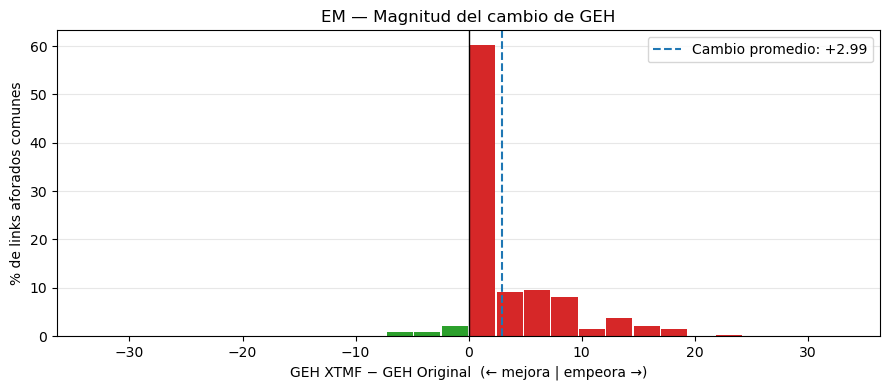

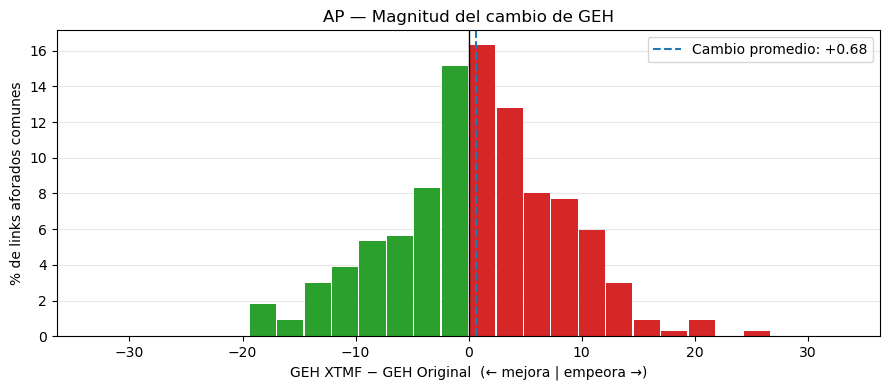

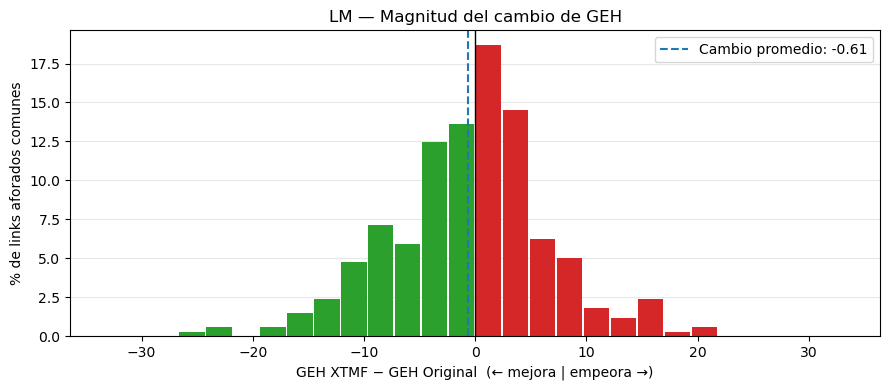

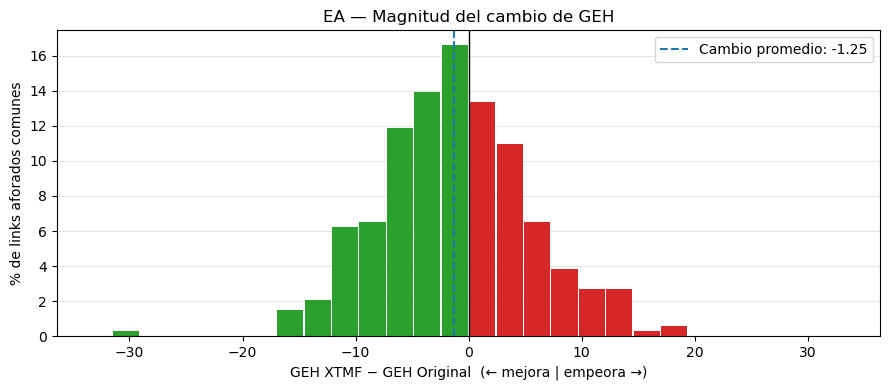

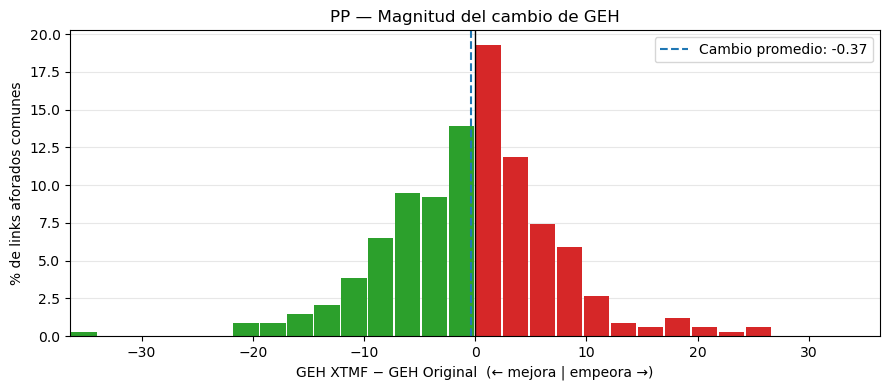

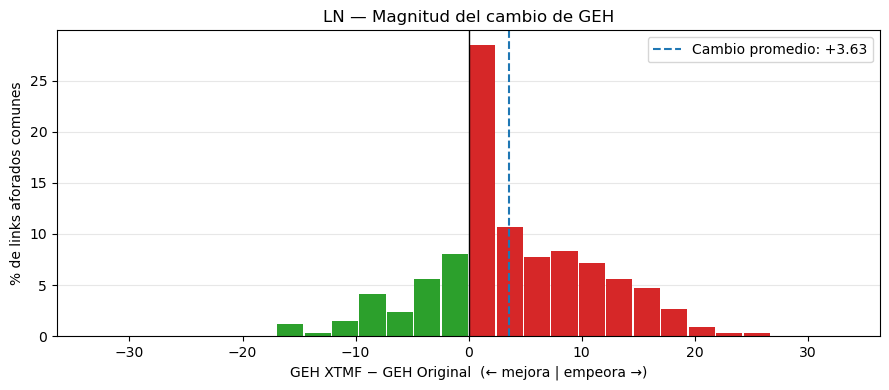

In [50]:
limite = max(
    detalle_cambios["Cambio GEH"].abs().max(),
    1
)

# Intervalos comunes, con cero como frontera
bins_cambio = np.linspace(-limite, limite, 31)
centros = (bins_cambio[:-1] + bins_cambio[1:]) / 2

for p in periodos:
    cambios = detalle_cambios.loc[
        detalle_cambios["periodo"] == p,
        "Cambio GEH"
    ]

    conteos, bordes = np.histogram(cambios, bins=bins_cambio)
    porcentajes = conteos / len(cambios) * 100

    fig, ax = plt.subplots(figsize=(9, 4))

    ax.bar(
        centros,
        porcentajes,
        width=np.diff(bordes) * 0.95,
        color=[
            "tab:green" if centro < 0 else "tab:red"
            for centro in centros
        ]
    )

    ax.axvline(0, color="black", linewidth=1)

    ax.axvline(
        cambios.mean(),
        color="tab:blue",
        linestyle="--",
        label=f"Cambio promedio: {cambios.mean():+.2f}"
    )

    ax.set(
        xlim=(-limite, limite),
        title=f"{p} — Magnitud del cambio de GEH",
        xlabel="GEH XTMF − GEH Original  (← mejora | empeora →)",
        ylabel="% de links aforados comunes"
    )

    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.legend()

    plt.tight_layout()
    plt.show()

In [51]:
revision = detalle_cambios.copy()

revision["Cambio GEH"] = (
    revision["GEH_xtmf"] - revision["GEH_original"]
)

# Diferencias de volumen: positivo = sobreestimación
revision["Error volumen Original"] = (
    revision["vol_modelado_original"] -
    revision["vol_observado"]
)

revision["Error volumen XTMF"] = (
    revision["vol_modelado_xtmf"] -
    revision["vol_observado"]
)

TOP = 10
TOL = 1e-6

revision["Revisar deterioro"] = False
revision["Revisar mejora"] = False
revision["Revisar GEH final alto"] = False

for p, grupo in revision.groupby("periodo", observed=True):

    # Mayores aumentos de GEH
    indices = (
        grupo[grupo["Cambio GEH"] > TOL]
        .nlargest(TOP, "Cambio GEH")
        .index
    )
    revision.loc[indices, "Revisar deterioro"] = True

    # Mayores reducciones de GEH
    indices = (
        grupo[grupo["Cambio GEH"] < -TOL]
        .nsmallest(TOP, "Cambio GEH")
        .index
    )
    revision.loc[indices, "Revisar mejora"] = True

    # Mayores errores finales en XTMF
    indices = grupo.nlargest(TOP, "GEH_xtmf").index
    revision.loc[indices, "Revisar GEH final alto"] = True

banderas = {
    "Revisar deterioro": "Mayor deterioro",
    "Revisar mejora": "Mayor mejora",
    "Revisar GEH final alto": "GEH final XTMF alto"
}

revision["Motivo de revisión"] = revision.apply(
    lambda fila: "; ".join(
        etiqueta
        for columna, etiqueta in banderas.items()
        if fila[columna]
    ),
    axis=1
)

columnas = [
    "periodo", "NO", "FROMNODENO", "TONODENO",
    "Motivo de revisión",
    "vol_observado",
    "vol_modelado_original", "vol_modelado_xtmf",
    "Error volumen Original", "Error volumen XTMF",
    "GEH_original", "GEH_xtmf", "Cambio GEH"
]

df_revision = (
    revision.loc[revision["Motivo de revisión"] != "", columnas]
    .sort_values(
        ["periodo", "Cambio GEH"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

# Mostrar sin modificar la precisión de los datos exportados
display(df_revision.round(2))

# Se guarda en la carpeta de trabajo del notebook
df_revision.to_csv(
    "links_para_revision_GEH.csv",
    index=False,
    encoding="utf-8-sig"
)

,periodo,NO,FROMNODENO,TONODENO,Motivo de revisión,vol_observado,vol_modelado_original,vol_modelado_xtmf,Error volumen Original,Error volumen XTMF,GEH_original,GEH_xtmf,Cambio GEH
0,AP,308460,126491,46850,Mayor deterioro,1558.94,1205,467,-353.94,-1091.94,9.52,34.31,24.79
1,AP,235382,93210,94120,Mayor deterioro,1109.91,1187,2064,77.09,954.09,2.27,23.95,21.68
2,AP,201736,79508,42187,Mayor deterioro,1759.38,1644,921,-115.38,-838.38,2.80,22.90,20.10
3,AP,261806,104988,131376,Mayor deterioro,912.71,807,337,-105.71,-575.71,3.60,23.03,19.43
4,AP,116002,46401,105285,Mayor deterioro,1804.99,1279,660,-525.99,-1144.99,13.39,32.61,19.22
...,...,...,...,...,...,...,...,...,...,...,...,...,...
171,PP,434516,179028,169835,Mayor mejora,4607.36,2342,3395,-2265.36,-1212.36,38.43,19.17,-19.26
172,PP,393285,161294,201527,Mayor mejora,787.52,248,695,-539.52,-92.52,23.71,3.40,-20.31
173,PP,4429,1520,1519,Mayor mejora,1237.29,471,1041,-766.29,-196.29,26.22,5.82,-20.40
174,PP,115834,46336,92234,Mayor mejora,701.36,210,668,-491.36,-33.36,23.02,1.27,-21.74


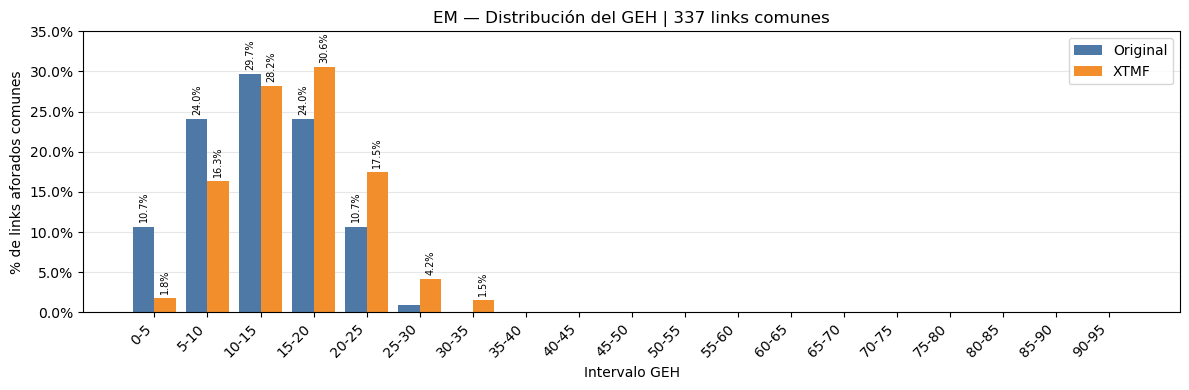

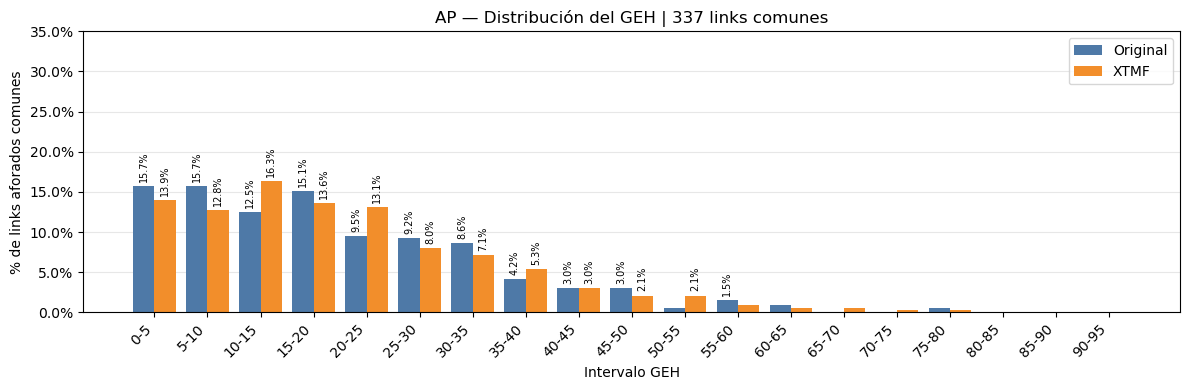

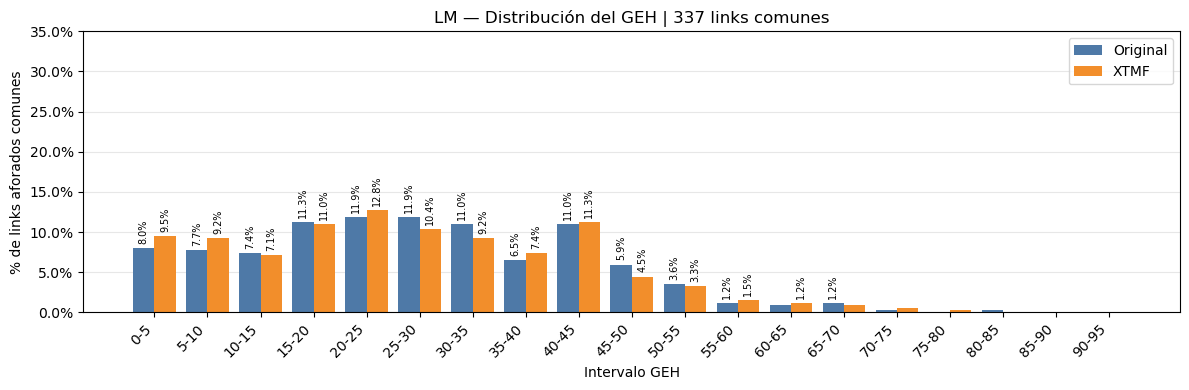

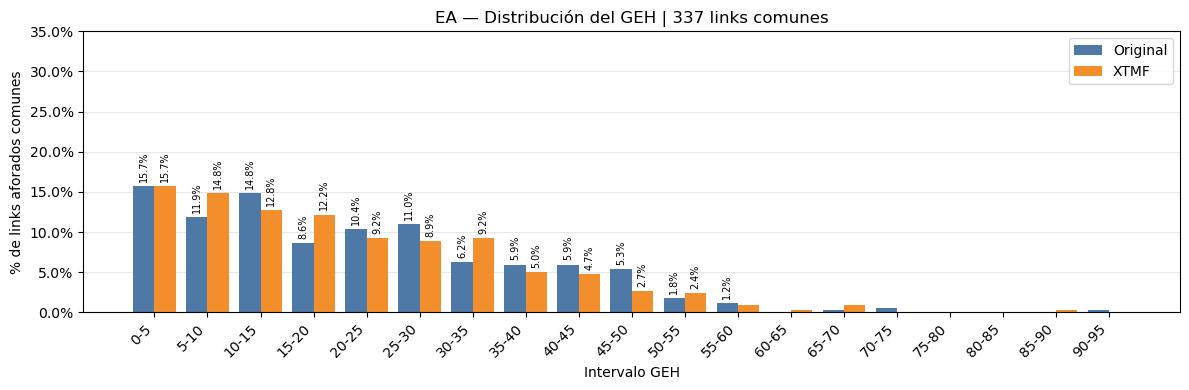

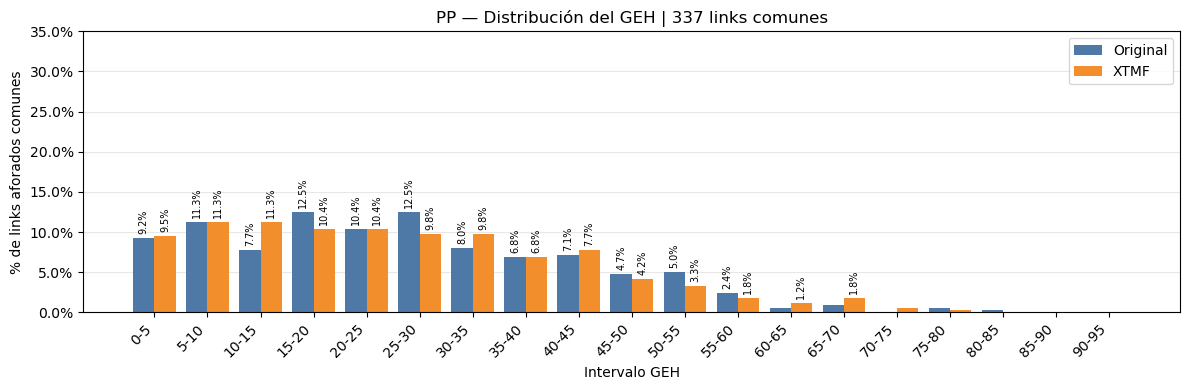

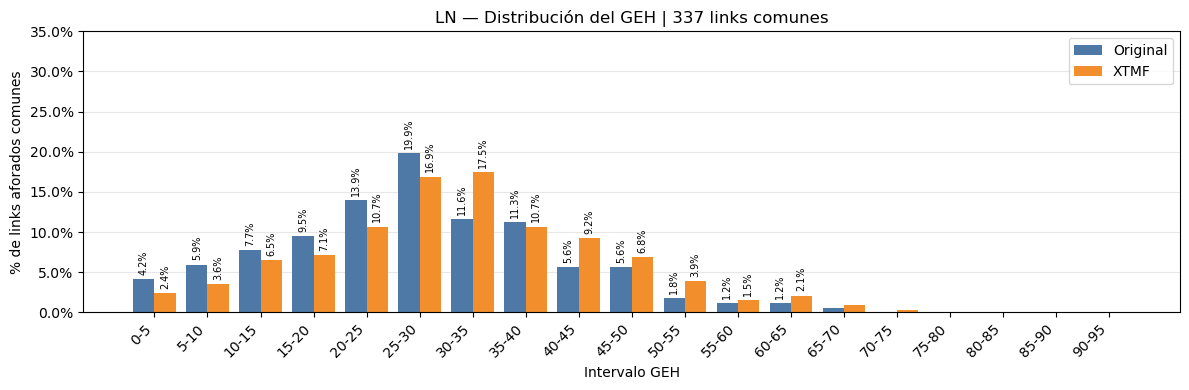

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Base completa de links aforados comunes
base = comparacion.copy()

columnas_geh = ["GEH_original", "GEH_xtmf"]

if base.empty:
    raise ValueError("La tabla comparacion está vacía.")

if (
    ~np.isfinite(base[columnas_geh].to_numpy(dtype=float))
).any() or (base[columnas_geh] < 0).any().any():
    raise ValueError("Hay valores GEH faltantes, no finitos o negativos.")

# Intervalos comunes de 5 en 5.
# El límite superior queda por encima del máximo de ambos escenarios.
max_geh = base[columnas_geh].max().max()
limite_superior = (int(np.floor(max_geh / 5)) + 1) * 5

bins_geh = np.arange(0, limite_superior + 1, 5)
labels_geh = [
    f"{inicio}-{fin}"
    for inicio, fin in zip(bins_geh[:-1], bins_geh[1:])
]

periodos_hist = [
    p for p in PERIODOS
    if p in base["periodo"].unique()
]

histogramas_geh = {}
max_porcentaje = 0

# Preparar distribuciones
for p in periodos_hist:
    d = base[base["periodo"] == p]

    tabla = pd.DataFrame(index=labels_geh)
    tabla.index.name = "Intervalo GEH"

    for columna, nombre in [
        ("GEH_original", "Original"),
        ("GEH_xtmf", "XTMF")
    ]:
        intervalos = pd.cut(
            d[columna],
            bins=bins_geh,
            labels=labels_geh,
            right=False
        )

        conteos = (
            intervalos.value_counts(sort=False)
            .reindex(labels_geh, fill_value=0)
        )

        tabla[f"Links {nombre}"] = conteos
        tabla[f"% {nombre}"] = conteos / len(d) * 100

    histogramas_geh[p] = tabla

    max_porcentaje = max(
        max_porcentaje,
        tabla[["% Original", "% XTMF"]].max().max()
    )

# Graficar con la misma escala vertical
limite_y = max(5, np.ceil((max_porcentaje + 3) / 5) * 5)

for p in periodos_hist:
    tabla = histogramas_geh[p]
    n_links = len(base[base["periodo"] == p])

    x = np.arange(len(labels_geh))
    ancho = 0.4

    fig, ax = plt.subplots(figsize=(12, 4))

    for desplazamiento, nombre, color in [
        (-ancho / 2, "Original", "#4E79A7"),
        (ancho / 2, "XTMF", "#F28E2B")
    ]:
        valores = tabla[f"% {nombre}"].to_numpy()

        barras = ax.bar(
            x + desplazamiento,
            valores,
            width=ancho,
            color=color,
            label=nombre
        )

        ax.bar_label(
            barras,
            labels=[
                f"{v:.1f}%" if v >= 1 else ""
                for v in valores
            ],
            padding=3,
            fontsize=7,
            rotation=90
        )

    ax.set_xticks(x)
    ax.set_xticklabels(labels_geh, rotation=45, ha="right")

    ax.set(
        title=f"{p} — Distribución del GEH | {n_links:,} links comunes",
        xlabel="Intervalo GEH",
        ylabel="% de links aforados comunes",
        ylim=(0, limite_y)
    )

    ax.yaxis.set_major_formatter(
        mticker.PercentFormatter(xmax=100)
    )
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.legend()

    plt.tight_layout()
    plt.show()

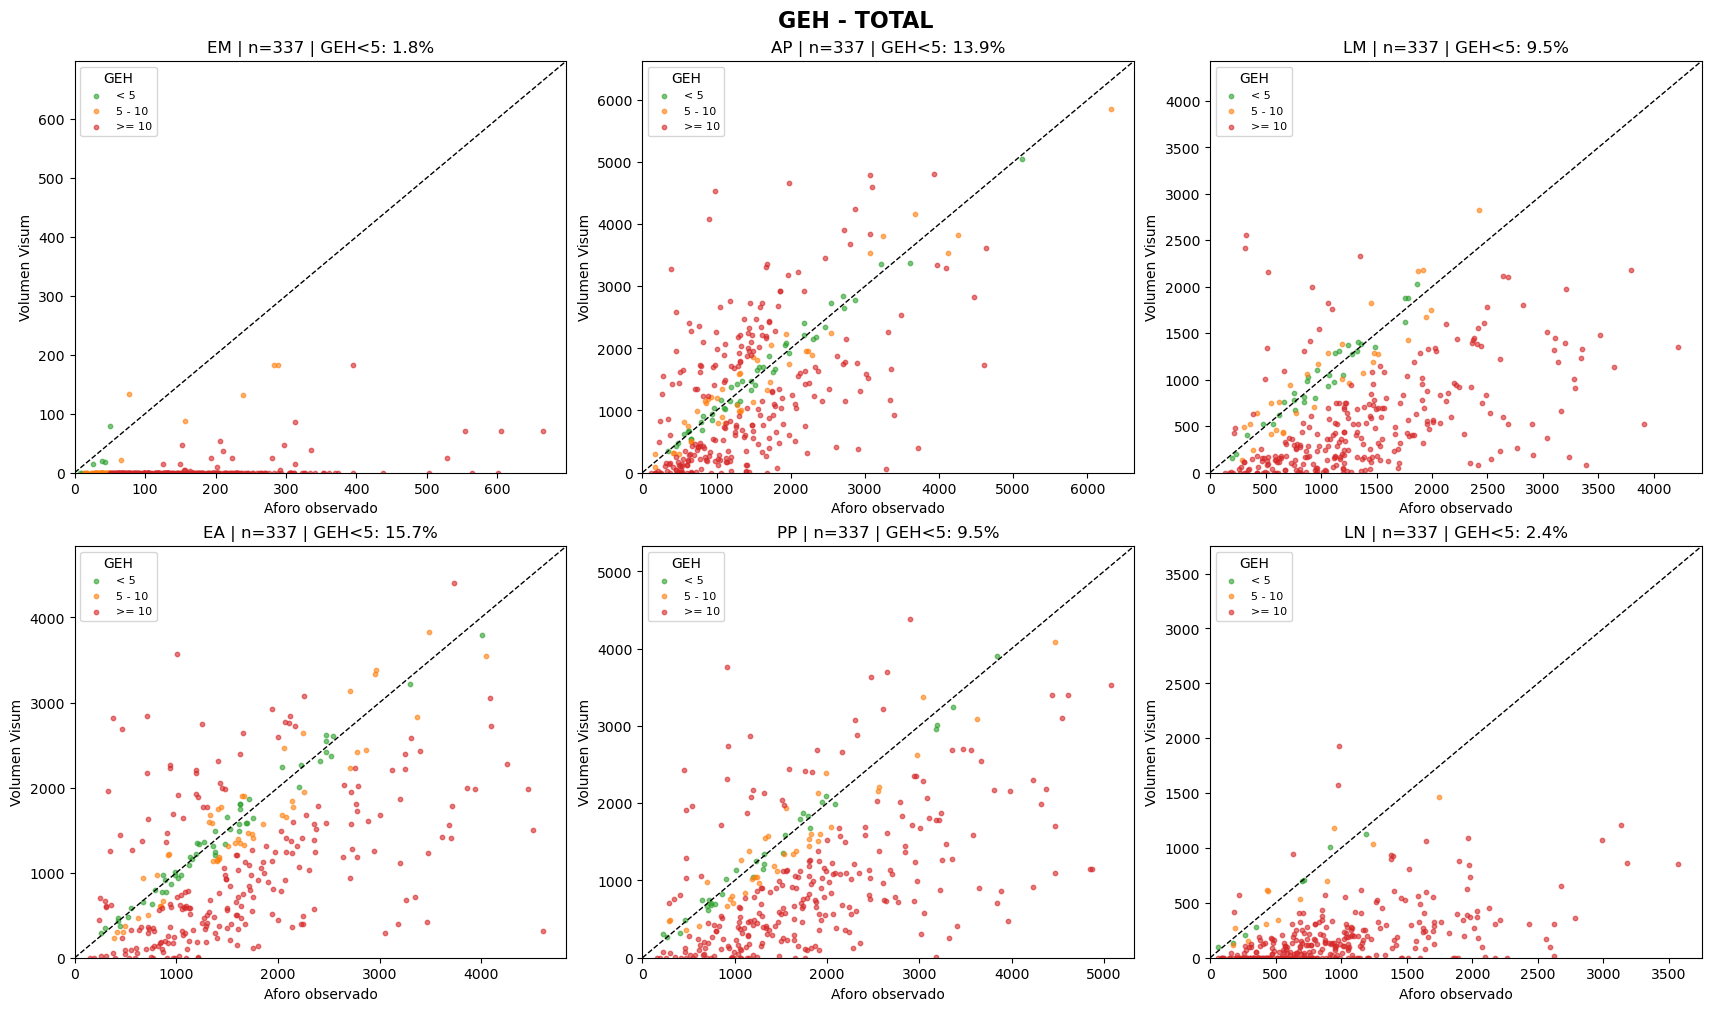

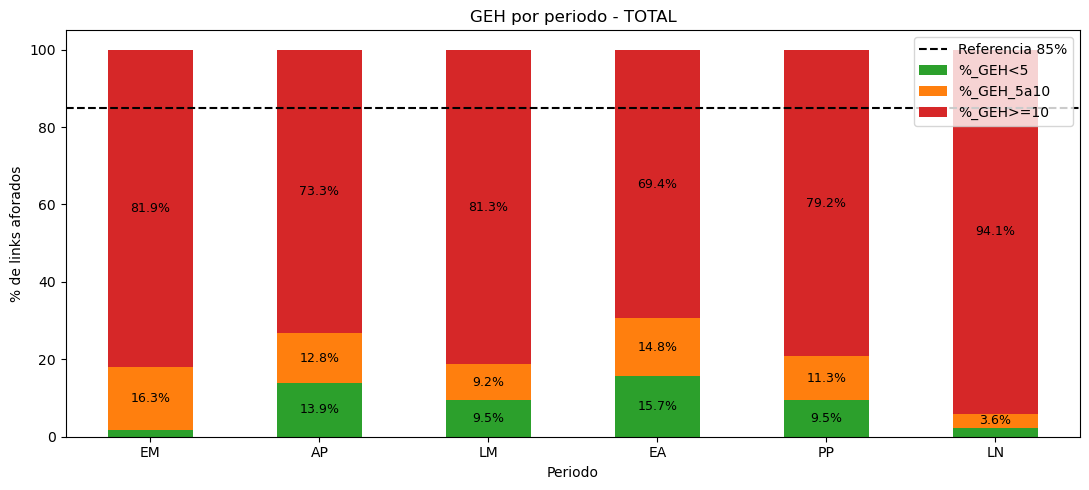

In [ ]:
colores = {
    "< 5": "tab:green",
    "5 - 10": "tab:orange",
    ">= 10": "tab:red"
}

for modo in ["TOTAL"]:

    # Filtrar únicamente el modo actual
    datos_modo = todo_xtmf[todo_xtmf["modo"] == modo]

    periodos = [
        p for p in PERIODOS
        if p in datos_modo["periodo"].unique()
    ]

    if not periodos:
        continue

    # ==========================================
    # 1. SCATTER PLOTS
    # ==========================================

    fig, axes = plt.subplots(
        2, 3,
        figsize=(17, 10),
        constrained_layout=True
    )

    fig.suptitle(
        f"GEH - {modo}",
        fontsize=16,
        fontweight="bold"
    )

    for ax, p in zip(axes.flat, periodos):

        d = datos_modo[datos_modo["periodo"] == p]

        for rango, color in colores.items():

            sub = d[d["rango_GEH"].astype(str) == rango]

            ax.scatter(
                sub["vol_observado"],
                sub["vol_modelado"],
                s=10,
                alpha=0.6,
                color=color,
                label=rango
            )

        # Línea de ajuste perfecto (modelado = observado)
        limite = max(
            d["vol_observado"].max(),
            d["vol_modelado"].max()
        ) * 1.05

        ax.plot(
            [0, limite],
            [0, limite],
            "k--",
            lw=1
        )

        ax.set(
            xlim=(0, limite),
            ylim=(0, limite),
            title=(
                f"{p} | n={len(d):,} | "
                f"GEH<5: {(d.GEH < 5).mean():.1%}"
            ),
            xlabel="Aforo observado",
            ylabel="Volumen Visum"
        )

        ax.legend(title="GEH", fontsize=8)

    # Ocultar subplots sin datos
    for ax in axes.flat[len(periodos):]:
        ax.set_visible(False)

    plt.show()

    # ==========================================
    # 2. BARRAS APILADAS POR PERIODO
    # ==========================================

    columnas_pct = [
        "%_GEH<5",
        "%_GEH_5a10",
        "%_GEH>=10"
    ]

    pct = (
        resumen_xtmf[resumen_xtmf["modo"] == modo]
        .set_index("periodo")
        .reindex(periodos)[columnas_pct]
        .astype(float)
    )

    ax = pct.plot.bar(
        stacked=True,
        figsize=(11, 5),
        color=[
            "tab:green",
            "tab:orange",
            "tab:red"
        ]
    )

    #  Porcentajes dentro de cada segmento
    for contenedor in ax.containers:
        ax.bar_label(
            contenedor,
            labels=[
                f"{valor:.1f}%" if valor >= 3 else ""
                for valor in contenedor.datavalues
            ],
            label_type="center",
            fontsize=9
        )

    ax.axhline(
        85,
        color="black",
        linestyle="--",
        label="Referencia 85%"
    )

    ax.set(
        ylabel="% de links aforados",
        xlabel="Periodo",
        title=f"GEH por periodo - {modo}"
    )

    ax.legend()
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()